<a href="https://colab.research.google.com/github/jetlambers1/r_portfolio/blob/main/JetLambers_familiarity_study_code_mask_processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

True

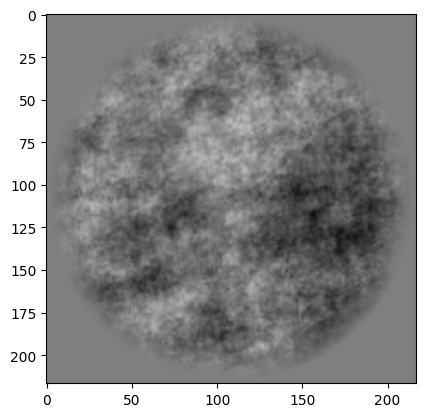

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from numpy import asarray

# create black image
#arr = np.full((217, 217, 3), 0, dtype=np.uint8) # this is your mask image (currently black)
arr = asarray(Image.open("mask_88.jpg"))
imgsize = arr.shape[:2]


outerColor = (127,127,127) # this is your background color (currently white)
innerBoundary = 90 # this defines the area of the mask unaffected by the gradient (needs tweaking)
outerBoundary = 108 # this defines the area of the background unaffected by the gradient (needs tweaking)
gradScale = 1/(outerBoundary-innerBoundary)

for y in range(imgsize[1]):
  for x in range(imgsize[0]):
    # find the distance to the centre
    distanceToCenter = np.sqrt((x - imgsize[0]//2) **2 + (y - imgsize[1]//2) ** 2)

    if distanceToCenter > innerBoundary:
      if distanceToCenter > outerBoundary:
        arr[y,x] = outerColor

      else:
        # scale from 0 to innerColor
        colorScale = (distanceToCenter-innerBoundary)*gradScale

        #calculate r, g, b values
        r = outerColor[0] * colorScale + arr[y,x,0] * (1-colorScale)
        g = outerColor[1] * colorScale + arr[y,x,1] * (1-colorScale)
        b = outerColor[2] * colorScale + arr[y,x,2] * (1-colorScale)

        # print r, g, and b
        arr[y,x] = (int(r), int(g), int(b))


plt.imshow(arr, cmap='gray')
plt.imsave("mask.jpg",arr)